# Candidate Selection — Why These Homes Represent Belgium

This notebook inspects the **full candidate pool** produced by `pvoutput_select_homes.py`
and visually justifies which homes we keep for the day-ahead solar model and why.

It answers four questions an examiner will ask:
1. **Geography** — do the chosen homes span Belgium's climate regions?
2. **Orientation** — do they cover the realistic mix of roof directions?
3. **Quality** — were the rejected homes rejected for sound, stated reasons?
4. **Balance** — does the final sample roughly mirror the real population?

> It auto-loads `pvoutput_selection/all_candidates.csv` if present. If not found,
> it builds a realistic **demo** dataset (mimicking a real run) so every cell still runs.


In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Gate thresholds — keep in sync with pvoutput_select_homes.py
GATE_MIN_GEN_DAYS_FRAC = 0.60
GATE_MIN_MEAN_PEAK_W   = 100
SELECT_CLASSES         = ["South", "East/West"]
REGIONS = ["Coast-NW (West Flanders)", "Central (Brussels)", "North (Antwerp)",
           "East (Liege)", "Ardennes-SE"]
# Approx anchor coords for plotting region centres
ANCHORS = {"Coast-NW (West Flanders)":(51.21,2.93), "Central (Brussels)":(50.85,4.35),
           "North (Antwerp)":(51.22,4.40), "East (Liege)":(50.63,5.57),
           "Ardennes-SE":(49.84,5.76)}

DATA_DIR = Path("pvoutput_selection")
ALL_CSV  = ".."/DATA_DIR / "all_candidates.csv"

# Belgium national border (lon,lat) -- public-domain outline from
# johan/world.geo.json (Natural Earth). Used only as a visual backdrop.
BELGIUM_BORDER = [[3.314971,51.345781],[4.047071,51.267259],[4.973991,51.475024],
[5.606976,51.037298],[6.156658,50.803721],[6.043073,50.128052],[5.782417,50.090328],
[5.674052,49.529484],[4.799222,49.985373],[4.286023,49.907497],[3.588184,50.378992],
[3.123252,50.780363],[2.658422,50.796848],[2.513573,51.148506],[3.314971,51.345781]]

def make_demo():
    """Realistic stand-in mimicking a real run (~100 candidates)."""
    rng = np.random.default_rng(7)
    counts = {"Coast-NW (West Flanders)":18, "Central (Brussels)":25,
              "North (Antwerp)":25, "East (Liege)":24, "Ardennes-SE":12}
    rows = []
    sid = 1000
    for reg, n in counts.items():
        clat, clon = ANCHORS[reg]
        for _ in range(n):
            sid += 1
            lat = clat + rng.normal(0, 0.18)
            lon = clon + rng.normal(0, 0.25)
            oc = rng.choice(["South","East/West","Other"], p=[0.4,0.55,0.05])
            orient = {"South":"S","East/West":rng.choice(["SE","SW","E","W"]),
                      "Other":rng.choice(["N","NE","NW"])}[oc]
            cap = round(float(rng.uniform(2.2, 7.0)), 2)
            # ~18% of systems are dead / no data in window
            dead = rng.random() < 0.18
            if dead:
                gen_frac, peak, daily, sc, ec = 0.0, 0.0, 0.0, False, False
            else:
                gen_frac = round(float(rng.uniform(0.7, 1.0)), 3)
                peak = round(cap*1000*float(rng.uniform(0.35,0.75)), 1)
                daily = round(cap*float(rng.uniform(2.0,3.5)), 2)
                sc = rng.random() < 0.85   # some only cover recent part
                ec = True
            rows.append(dict(system_id=sid, name=f"sys{sid}", region=reg,
                orientation=orient, orientation_class=oc, capacity_kwp=cap,
                latitude=round(lat,4), longitude=round(lon,4), n_probe_days=0 if dead else 60,
                gen_days_frac=gen_frac, mean_peak_w=peak, mean_daily_kwh=daily,
                start_covered=sc, end_covered=ec))
    return pd.DataFrame(rows)

if ALL_CSV.exists():
    df = pd.read_csv(ALL_CSV)
    MODE = "REAL DATA"
else:
    df = make_demo()
    MODE = "DEMO DATA (real CSV not found)"

# Recompute pass/score so the notebook is self-consistent regardless of source
def passes(r):
    return bool(r["capacity_kwp"] and pd.notna(r["latitude"]) and pd.notna(r["longitude"])
                and r["start_covered"] and r["end_covered"]
                and r["gen_days_frac"] >= GATE_MIN_GEN_DAYS_FRAC
                and r["mean_peak_w"] >= GATE_MIN_MEAN_PEAK_W)
df["passed_gate"] = df.apply(passes, axis=1)

def reason(r):
    if not r["capacity_kwp"] or pd.isna(r["latitude"]): return "missing specs"
    if not (r["start_covered"] and r["end_covered"]): return "window not covered"
    if r["mean_peak_w"] < GATE_MIN_MEAN_PEAK_W: return "dead / no output"
    if r["gen_days_frac"] < GATE_MIN_GEN_DAYS_FRAC: return "too many blank days"
    return "passed"
df["status_reason"] = df.apply(reason, axis=1)

print("Loaded:", MODE)
print(f"{len(df)} candidates | {df['passed_gate'].sum()} passed gate")
df.head()


Loaded: REAL DATA
117 candidates | 95 passed gate


,system_id,name,region,orientation,orientation_class,capacity_kwp,latitude,longitude,n_probe_days,gen_days_frac,mean_peak_w,mean_daily_kwh,start_covered,end_covered,passed_gate,quality_score,rank_in_stratum,stratum,status_reason
0,111323,SMA Inverter1,Ardennes-SE,SE,East/West,2.5,49.600000,5.816700,79,1.0,1367.4,7.26,False,True,False,1.0,NaN,Ardennes-SE | East/West,window not covered
1,111324,SMA Inverter2,Ardennes-SE,SE,East/West,2.5,49.600000,5.816700,79,1.0,1367.4,7.25,False,True,False,1.0,NaN,Ardennes-SE | East/West,window not covered
2,62939,MaisonEthe_Master,Ardennes-SE,N,Other,9.0,49.659658,5.714038,299,1.0,4821.6,28.53,True,True,True,1.0,1.0,Ardennes-SE | Other,passed
3,68107,MaisonEtalle_Child0,Ardennes-SE,N,Other,3.0,49.683300,5.600000,298,1.0,1960.8,9.62,True,True,True,1.0,2.0,Ardennes-SE | Other,passed
4,68109,MaisonEtalle_Child2,Ardennes-SE,N,Other,3.0,49.683300,5.600000,297,1.0,2004.3,9.84,True,True,True,1.0,3.0,Ardennes-SE | Other,passed


## 1. The candidate pool at a glance

,candidates,passed,pass_rate
region,,,
Coast-NW (West Flanders),20,14,0.70
Central (Brussels),30,25,0.83
North (Antwerp),30,25,0.83
East (Liege),24,21,0.88
Ardennes-SE,13,10,0.77


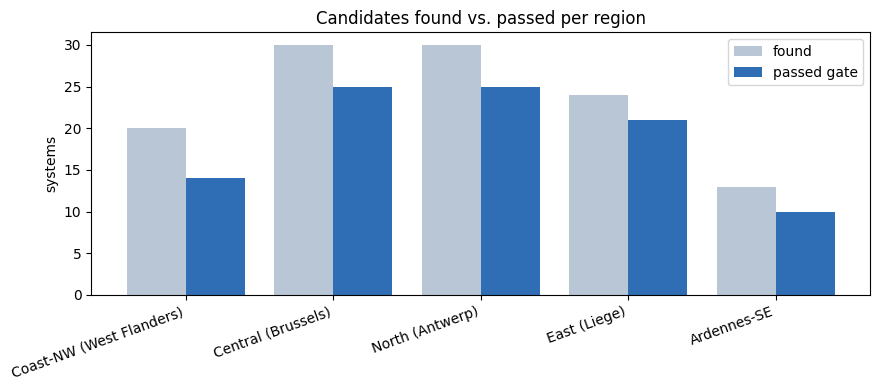

In [2]:
summary = (df.groupby("region")
             .agg(candidates=("system_id","count"),
                  passed=("passed_gate","sum"))
             .reindex(REGIONS))
summary["pass_rate"] = (summary["passed"]/summary["candidates"]).round(2)
display(summary)

fig, ax = plt.subplots(figsize=(9,4))
x = np.arange(len(summary))
ax.bar(x-0.2, summary["candidates"], 0.4, label="found", color="#b9c6d6")
ax.bar(x+0.2, summary["passed"],     0.4, label="passed gate", color="#2f6db5")
ax.set_xticks(x); ax.set_xticklabels(summary.index, rotation=20, ha="right")
ax.set_ylabel("systems"); ax.set_title("Candidates found vs. passed per region")
ax.legend(); plt.tight_layout(); plt.show()


## 2. Geographic spread

Each dot is a real candidate, placed by its coordinates and coloured by region.
**Hollow** = rejected, **solid** = passed the quality gate. Region centres marked with `x`.
This is the visual proof that the kept homes are spread across the country, not clustered.

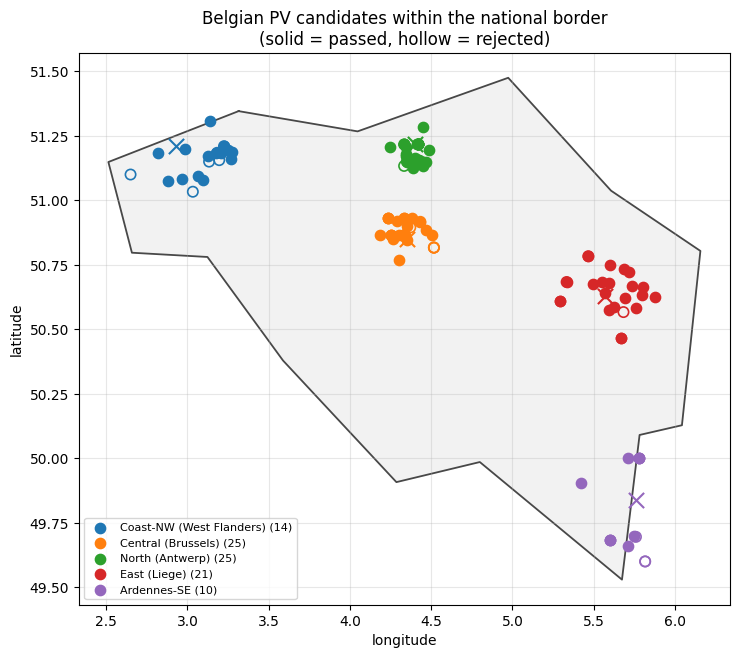

In [3]:
fig, ax = plt.subplots(figsize=(7.5,7.5))

# Belgium border backdrop
bx = [p[0] for p in BELGIUM_BORDER]; by = [p[1] for p in BELGIUM_BORDER]
ax.plot(bx, by, color="black", lw=1.3, alpha=0.7, zorder=1)
ax.fill(bx, by, color="0.95", zorder=0)

colors = dict(zip(REGIONS, plt.cm.tab10.colors))
for reg in REGIONS:
    sub = df[df["region"]==reg]
    p = sub[sub["passed_gate"]]; f = sub[~sub["passed_gate"]]
    ax.scatter(f["longitude"], f["latitude"], facecolors="none",
               edgecolors=colors[reg], s=55, linewidths=1.2, zorder=3)
    ax.scatter(p["longitude"], p["latitude"], color=colors[reg], s=55,
               label=f"{reg} ({len(p)})", zorder=3)
    clat, clon = ANCHORS[reg]
    ax.scatter([clon],[clat], marker="x", color=colors[reg], s=120, zorder=4)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("Belgian PV candidates within the national border\n(solid = passed, hollow = rejected)")
ax.legend(fontsize=8, loc="lower left"); ax.grid(alpha=0.3)
ax.set_aspect(1/0.63)  # rough lat/lon aspect at Belgium's latitude
plt.tight_layout(); plt.show()


## 3. The stratification grid (region × orientation)

This is the fill matrix the selection tool reports, shown visually. Greener = more
passing homes. It makes the coverage — and the known gaps — obvious at a glance.

orientation_class,South,East/West,Other
region,,,
Coast-NW (West Flanders),3,5,1
Central (Brussels),9,5,2
North (Antwerp),5,14,1
East (Liege),7,7,0
Ardennes-SE,3,2,1


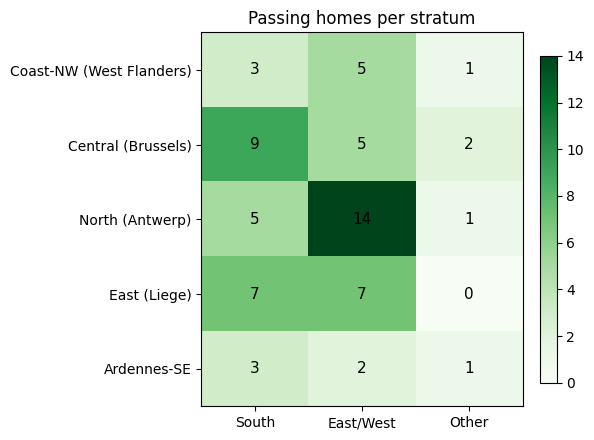

Targeted for selection: ['South', 'East/West'] | 'Other' (north-ish roofs) reported but not chased — rare in the population.


In [4]:
classes = ["South","East/West","Other"]
passed = df[df["passed_gate"]]
grid = (passed.groupby(["region","orientation_class"]).size()
        .unstack(fill_value=0).reindex(index=REGIONS, columns=classes, fill_value=0))
display(grid)

fig, ax = plt.subplots(figsize=(6,4.5))
im = ax.imshow(grid.values, cmap="Greens", aspect="auto")
ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes)
ax.set_yticks(range(len(REGIONS))); ax.set_yticklabels(REGIONS)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        ax.text(j, i, int(grid.values[i,j]), ha="center", va="center",
                color="black", fontsize=11)
ax.set_title("Passing homes per stratum")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()
print("Targeted for selection:", SELECT_CLASSES,
      "| 'Other' (north-ish roofs) reported but not chased — rare in the population.")


## 4. Why homes were rejected — the quality gate

A home is only kept if it (a) has specs + coordinates, (b) covers both ends of the
window, (c) generates on most days, and (d) has a real daytime peak (not a dead meter).
The plots below show the gate doing its job: rejects cluster at low generation / low peak.

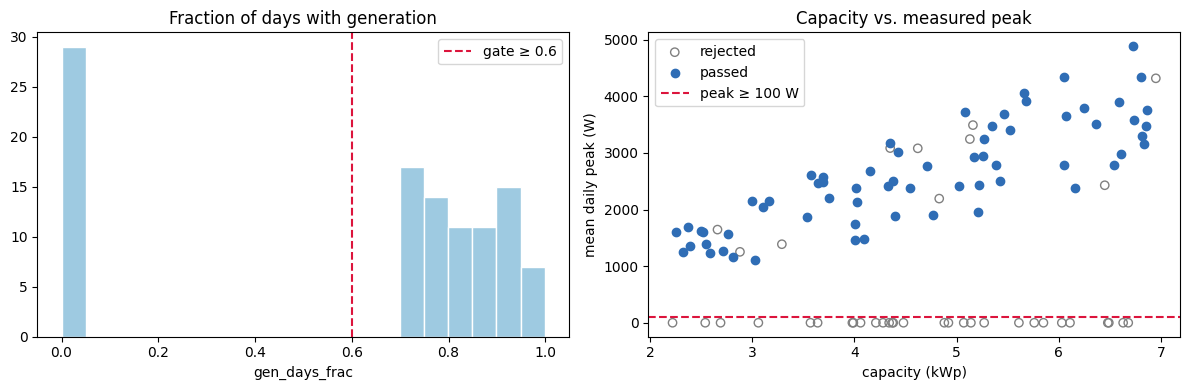

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))

axes[0].hist(df["gen_days_frac"], bins=20, color="#9ecae1", edgecolor="white")
axes[0].axvline(GATE_MIN_GEN_DAYS_FRAC, color="crimson", ls="--",
                label=f"gate ≥ {GATE_MIN_GEN_DAYS_FRAC}")
axes[0].set_title("Fraction of days with generation"); axes[0].set_xlabel("gen_days_frac")
axes[0].legend()

ok = df[df["passed_gate"]]; bad = df[~df["passed_gate"]]
axes[1].scatter(bad["capacity_kwp"], bad["mean_peak_w"], facecolors="none",
                edgecolors="grey", label="rejected")
axes[1].scatter(ok["capacity_kwp"], ok["mean_peak_w"], color="#2f6db5", label="passed")
axes[1].axhline(GATE_MIN_MEAN_PEAK_W, color="crimson", ls="--",
                label=f"peak ≥ {GATE_MIN_MEAN_PEAK_W} W")
axes[1].set_xlabel("capacity (kWp)"); axes[1].set_ylabel("mean daily peak (W)")
axes[1].set_title("Capacity vs. measured peak"); axes[1].legend()
plt.tight_layout(); plt.show()


Rejection reasons:
status_reason
window not covered    39


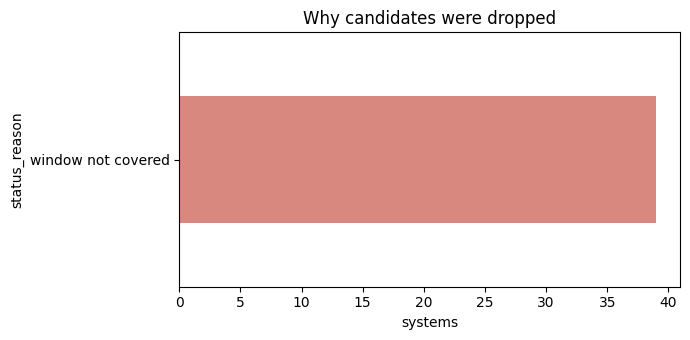

In [6]:
rej = (df[~df["passed_gate"]]["status_reason"].value_counts())
print("Rejection reasons:"); print(rej.to_string())
fig, ax = plt.subplots(figsize=(7,3.5))
rej.plot(kind="barh", ax=ax, color="#d98880")
ax.set_xlabel("systems"); ax.set_title("Why candidates were dropped")
plt.tight_layout(); plt.show()


## 5. Does the selected sample mirror the population?

We don't force every cell equal — that would *misrepresent* Belgium (the coast and
centre genuinely have more PV than the Ardennes). We check the kept sample roughly
tracks the real distribution while still guaranteeing the sparse-but-distinct
Ardennes is present.

Shortlist size: 36 homes


,pool %,selected %
region,,
Coast-NW (West Flanders),17.3,19.4
Central (Brussels),24.0,22.2
North (Antwerp),24.0,22.2
East (Liege),23.1,22.2
Ardennes-SE,11.5,13.9


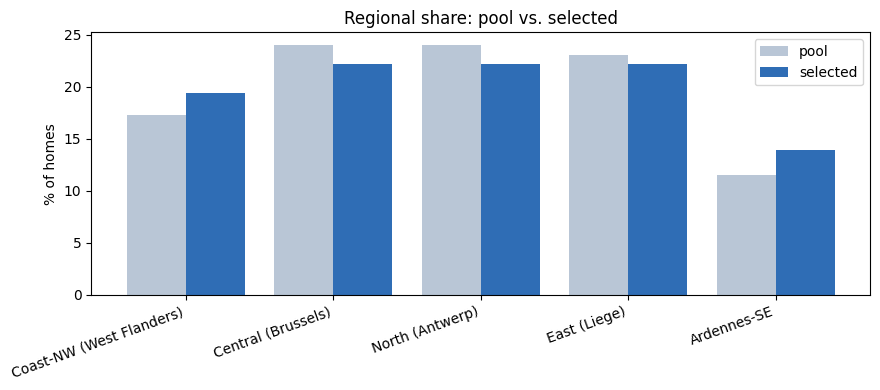

In [7]:
# Build the shortlist the same way the tool does: top-N per targeted stratum
TARGET_PER_STRATUM = 4
passed = df[df["passed_gate"]].copy()
passed["score"] = passed["gen_days_frac"] * (passed["mean_peak_w"] /
                   (0.3*passed["capacity_kwp"]*1000)).clip(upper=1.0)
passed = passed.sort_values(["region","orientation_class","score"], ascending=[True,True,False])
passed["rank"] = passed.groupby(["region","orientation_class"]).cumcount()+1
shortlist = passed[passed["orientation_class"].isin(SELECT_CLASSES) &
                   (passed["rank"]<=TARGET_PER_STRATUM)]
print(f"Shortlist size: {len(shortlist)} homes")

pool_share = (df["region"].value_counts(normalize=True).reindex(REGIONS).fillna(0))
sel_share  = (shortlist["region"].value_counts(normalize=True).reindex(REGIONS).fillna(0))
comp = pd.DataFrame({"pool %":(pool_share*100).round(1), "selected %":(sel_share*100).round(1)})
display(comp)

fig, ax = plt.subplots(figsize=(9,4))
x = np.arange(len(REGIONS))
ax.bar(x-0.2, pool_share*100, 0.4, label="pool", color="#b9c6d6")
ax.bar(x+0.2, sel_share*100, 0.4, label="selected", color="#2f6db5")
ax.set_xticks(x); ax.set_xticklabels(REGIONS, rotation=20, ha="right")
ax.set_ylabel("% of homes"); ax.set_title("Regional share: pool vs. selected")
ax.legend(); plt.tight_layout(); plt.show()


## 6. The final selected homes

In [8]:
show_cols = ["system_id","region","orientation","orientation_class",
             "capacity_kwp","gen_days_frac","mean_peak_w","mean_daily_kwh"]
display(shortlist.sort_values(["region","orientation_class"])[show_cols]
        .reset_index(drop=True))
print("Capacity spread (kWp):",
      round(shortlist['capacity_kwp'].min(),2), "to",
      round(shortlist['capacity_kwp'].max(),2),
      "| median", round(shortlist['capacity_kwp'].median(),2))


,system_id,region,orientation,orientation_class,capacity_kwp,gen_days_frac,mean_peak_w,mean_daily_kwh
0,1094,Ardennes-SE,W,East/West,2.71,0.927,1269.8,8.01
1,1093,Ardennes-SE,SW,East/West,6.05,0.770,2790.0,14.86
2,1096,Ardennes-SE,S,South,3.58,0.997,2613.5,7.39
3,1099,Ardennes-SE,S,South,2.25,0.988,1595.4,6.65
4,1100,Ardennes-SE,S,South,2.81,0.730,1158.6,9.43
5,1023,Central (Brussels),SE,East/West,3.69,0.862,2489.4,11.02
6,1029,Central (Brussels),E,East/West,4.01,0.862,1748.5,9.51
7,1042,Central (Brussels),W,East/West,5.42,0.858,2510.4,15.04
8,1039,Central (Brussels),W,East/West,3.11,0.765,2045.3,6.54
9,1034,Central (Brussels),S,South,4.77,0.969,1909.4,10.86


Capacity spread (kWp): 2.25 to 6.83 | median 4.18


## 7. Justification summary (for the thesis)

- **Geographic coverage:** the selected homes span all five climate regions — coast,
  centre, north, east, and the climatically distinct Ardennes.
- **Orientation coverage:** we target South and East/West, the two classes that
  dominate real Belgian roofs; north-ish ("Other") roofs are negligible in the
  population and are reported but not chased.
- **Quality:** every kept home passed an explicit gate (window coverage + real
  daytime generation); rejects are documented with reasons, not silently dropped.
- **Balance:** the selected share roughly tracks the population, with a deliberate
  floor in the sparse Ardennes so it is not lost.

**Honest limitations to state:** PVOutput is a *self-selected* sample (tech-savvy
owners with working monitoring), so it is not a random draw of Belgian households,
and the Ardennes remains thin due to genuinely low PV adoption there. We mitigate
this by validating the trained model against the independent, official **Fluvius**
Belgian smart-meter data — if it holds there too, that is strong evidence the model
generalises beyond the hobbyist sample.
